# AgriFlight-RL: algorithm comparison (PPO vs REINFORCE vs A2C vs baselines)

**Team LMF ("Let me fly")**, 43008 Reinforcement Learning, UTS Spring 2026, Assessment 3.

This notebook trains nothing. It reads the results each member saved from their own notebook and puts the
three algorithms side by side on the same levels, seeds and evaluation protocol:

| Algorithm | Owner | Source in `results/` |
| --------- | ----- | -------------------- |
| PPO | Nelkit Chavez (25609227) | `ppo_25609227.json` (shared schema, every run under `training.runs`) |
| REINFORCE | Juan David Rodriguez (25418551) | `reinforce_25418551.json` (shared schema, same layout as PPO) |
| A2C | Panzhao Li (25399217) | one file per run: `a2c_25399217_L{level}_seed{seed}_<run id>.json` |

Protocol shared by all three: levels L0-L4, training seeds 0-2, 1M environment steps per run, deterministic
evaluation (Gaussian mean) on the held-out seeds 1000-1019, reward v1 with `crash_penalty = 300`.

The only thing evaluated here is the **cruise-and-centre** baseline (Juan's proposal: forward 1.0,
sideways = -offset, altitude hold), because no results file contains it. It is a fixed controller, so it takes
seconds. The other baselines (zero action, altitude-hold, random) are read from the results files.

## 1. Setup

In [1]:
import os, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym

def find_repo_root(start):
    p = Path(start).resolve()
    for d in (p, *p.parents):
        if (d / "pyproject.toml").is_file():
            return d
    return None

# Run from inside a clone of the repo (locally, or on SageMaker after cloning it; see docs/sagemaker_setup.md)
_nb_file = globals().get("__vsc_ipynb_file__")   # set by VS Code, None elsewhere
REPO = next((r for r in map(find_repo_root, ([Path(_nb_file).parent] if _nb_file else []) + [Path.cwd()]) if r), None)
if REPO is None:
    raise RuntimeError("agroflight-rl repo not found: open this notebook from inside your clone.")
os.chdir(REPO)
os.environ.setdefault("AGRO_DRONE_XML", str(REPO / "mujoco_menagerie" / "skydio_x2" / "x2.xml"))

import agroflight.envs  # noqa: F401  (registers AgroDrone-v0)
from agroflight.envs import ENV_ID
from agroflight.evaluation.evaluate_policy import evaluate
from agroflight.baselines import cruise_and_centre_action

RESULTS_DIR, FIG_DIR = REPO / "results", REPO / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

LEVELS, SEEDS = list(range(5)), list(range(3))
EVAL_SEEDS = list(range(1000, 1020))
REWARD_CONFIG = dict(crash_penalty=300.0)   # the env default since 17 Oct; passed explicitly, as the notebooks do
LEVEL_NAMES = {0: "L0 hover", 1: "L1 offset start", 2: "L2 crosswind", 3: "L3 gusts", 4: "L4 gusts + yaw"}

ALGOS = ["PPO", "REINFORCE", "A2C"]
BASELINES = ["altitude_hold", "random", "cruise_and_centre"]
LABEL = {"altitude_hold": "altitude-hold", "random": "random", "cruise_and_centre": "cruise-and-centre"}
# Algorithms: fixed categorical order (validated for colour-vision deficiency). Baselines: neutral greys,
# cruise-and-centre the darkest and hatched because it is the bar to beat.
COLOR = {"PPO": "#2a78d6", "REINFORCE": "#eb6834", "A2C": "#1baf7a",
         "altitude_hold": "#b8bcc4", "random": "#d9dce1", "cruise_and_centre": "#6b7280"}
HATCH = {"cruise_and_centre": "//"}
print("repo:", REPO)

repo: /Users/nelkitchavezcalona/Projects/UTS/RL/Reinforcement Learning - AT3/agroflight-rl


## 2. Load the results

Every run is reduced to the same record, whatever file it came from:
`final` and `best` checkpoint metrics, the periodic checkpoints in step order (for "samples to clear") and the
training curve. The final checkpoint is the headline number in all three notebooks, so it is the headline here;
`best` is shown separately in section 6.

In [2]:
def from_shared_schema(path):
    """PPO and REINFORCE: one file, every run under training.runs, checkpoint_eval keyed by file name."""
    data = json.load(open(path))
    runs = {}
    for r in data["training"]["runs"].values():
        ce = r["checkpoint_eval"]
        runs[(r["level"], r["train_seed"])] = dict(
            total_timesteps=r["total_timesteps"],
            final=ce["final.pt"], best=ce["best.pt"],
            checkpoints=sorted(((v["timesteps"], v) for k, v in ce.items() if k != "best.pt"), key=lambda c: c[0]),
            curve=[(p["timesteps"], p["mean_return"]) for p in r["curve"]])
    return data, runs

def from_a2c_files(pattern="a2c_25399217_L?_seed?_*.json"):
    """A2C: one file per run, checkpoints as a list with a role. Older files with other names are skipped."""
    runs = {}
    for path in sorted(RESULTS_DIR.glob(pattern)):
        d = json.load(open(path))
        t, ev = d["training"], d["evaluation"]
        key = (t["level"], t["train_seed"])
        assert key not in runs, f"two A2C files for L{key[0]} seed {key[1]}: {path.name}"
        role = {c["role"]: c for c in ev["checkpoints"]}
        assert role["final"]["metrics"]["mean_reward"] == ev["levels"][f"L{key[0]}"]["mean_reward"]
        runs[key] = dict(
            total_timesteps=t["total_timesteps"],
            final=role["final"]["metrics"], best=role["best"]["metrics"],
            checkpoints=sorted(((c["timesteps"], c["metrics"]) for c in ev["checkpoints"] if c["role"] != "best"),
                               key=lambda c: c[0]),
            curve=[(p["timesteps"], p["mean_return"]) for p in t["curve"]])
    return runs

ppo_data, ppo_runs = from_shared_schema(RESULTS_DIR / "ppo_25609227.json")
rf_data, rf_runs = from_shared_schema(RESULTS_DIR / "reinforce_25418551.json")
RUNS = {"PPO": ppo_runs, "REINFORCE": rf_runs, "A2C": from_a2c_files()}

for algo, runs in RUNS.items():
    missing = [(lv, s) for lv in LEVELS for s in SEEDS if (lv, s) not in runs]
    budgets = sorted({r["total_timesteps"] for r in runs.values()})
    print(f"{algo:<9} {len(runs)} runs  budget {budgets}  missing {missing or 'none'}")
    assert not missing

PPO       15 runs  budget [1000000]  missing none
REINFORCE 15 runs  budget [1000000, 1000053, 1000195, 1000368, 1000380, 1000386, 1000474, 1000491, 1000570, 1000647, 1000665, 1000676, 1000881]  missing none
A2C       15 runs  budget [1000000]  missing none


## 3. Baselines

Zero action, altitude-hold and random come from the PPO and REINFORCE files, which evaluated them with the same
code, seeds and random generator (`xxx@L{level}`). The check below confirms the two files agree before using them.
A2C evaluated its own random baseline with a different generator, so its numbers differ slightly and are not used.

Cruise-and-centre is evaluated here, with the same `evaluate()` harness and held-out seeds as every algorithm.

In [3]:
ppo_b, rf_b = ppo_data["evaluation"]["baselines"], rf_data["evaluation"]["baselines"]
for k in (f"{b}@L{lv}" for b in ("zero_action", "altitude_hold", "random") for lv in LEVELS):
    assert np.isclose(ppo_b[k]["mean_reward"], rf_b[k]["mean_reward"]), k
BASE = {(b, lv): ppo_b[f"{b}@L{lv}"] for b in ("zero_action", "altitude_hold", "random") for lv in LEVELS}

t0 = time.time()
for lv in LEVELS:
    env = gym.make(ENV_ID, level=lv, reward_config=REWARD_CONFIG)
    BASE[("cruise_and_centre", lv)] = evaluate(cruise_and_centre_action, seeds=EVAL_SEEDS, env=env)
    env.close()
print(f"cruise-and-centre evaluated on L0-L4 x {len(EVAL_SEEDS)} episodes in {time.time() - t0:.0f} s\n")

pd.DataFrame({LABEL.get(b, b): {f"L{lv}": BASE[(b, lv)]["mean_reward"] for lv in LEVELS}
              for b in ("zero_action", *BASELINES)}).round(1)

cruise-and-centre evaluated on L0-L4 x 20 episodes in 6 s



,zero_action,altitude-hold,random,cruise-and-centre
L0,14.9,19.8,6.5,6.4
L1,-1.0,3.9,-9.9,99.7
L2,-716.9,-712.7,-738.2,90.1
L3,-163.8,-153.4,-176.1,95.8
L4,-163.8,-153.4,-177.9,95.6


## 4. Did each algorithm clear each level?

Same criterion as the PPO and REINFORCE notebooks (and A2C's `pass_criterion`): crash rate at most 5 % and, on L0,
mean |altitude error| under 0.05 m; on L1-L4, at least 90 % of the rows finished.
**Samples to clear** = environment steps of the first periodic checkpoint (every 100k, or the final one) that
clears the level, which is how all three notebooks measure sample cost.

In [4]:
def cleared(st, level):
    if st["crash_rate"] > 0.05:
        return False
    return st["mean_abs_alt_error"] < 0.05 if level == 0 else st["finish_rate"] >= 0.90

def samples_to_clear(run, level):
    return next((t for t, st in run["checkpoints"] if cleared(st, level)), None)

rows = []
for algo, runs in RUNS.items():
    for lv in LEVELS:
        finals = [runs[(lv, s)]["final"] for s in SEEDS]
        n_steps = [samples_to_clear(runs[(lv, s)], lv) for s in SEEDS]
        rows.append(dict(
            algorithm=algo, level=f"L{lv}",
            mean_reward=np.mean([f["mean_reward"] for f in finals]),
            seed_std=np.std([f["mean_reward"] for f in finals]),
            crash_rate=np.mean([f["crash_rate"] for f in finals]),
            finish_rate=np.mean([f["finish_rate"] for f in finals]),
            alt_error_m=np.mean([f["mean_abs_alt_error"] for f in finals]),
            seeds_cleared=sum(cleared(f, lv) for f in finals),
            samples_to_clear=" / ".join(f"{n // 1000}k" if n else "-" for n in n_steps)))
summary = pd.DataFrame(rows).set_index(["algorithm", "level"])

for lv in LEVELS:   # the baselines, with the same criterion, for reference
    st = BASE[("cruise_and_centre", lv)]
    summary.loc[("cruise-and-centre", f"L{lv}"), :] = dict(
        mean_reward=st["mean_reward"], seed_std=np.nan, crash_rate=st["crash_rate"], finish_rate=st["finish_rate"],
        alt_error_m=st["mean_abs_alt_error"], seeds_cleared=int(cleared(st, lv)), samples_to_clear="(not learned)")

summary.style.format({"mean_reward": "{:.1f}", "seed_std": "{:.1f}", "crash_rate": "{:.0%}",
                      "finish_rate": "{:.0%}", "alt_error_m": "{:.3f}", "seeds_cleared": "{:.0f}"})

In [5]:
# Headline for the report: highest level cleared by the final checkpoint of all 3 seeds, and by at least 2 of 3
def highest(algo, min_seeds):
    ok = [lv for lv in LEVELS if summary.loc[(algo, f"L{lv}"), "seeds_cleared"] >= min_seeds]
    return f"L{max(ok)}" if ok else "none"

headline = pd.DataFrame({algo: {"highest level, 3/3 seeds": highest(algo, 3),
                                "highest level, >= 2/3 seeds": highest(algo, 2),
                                "levels cleared (3/3 seeds)": sum(summary.loc[(algo, f"L{lv}"), "seeds_cleared"] == 3
                                                                  for lv in LEVELS)}
                         for algo in ALGOS}).T
headline

,"highest level, 3/3 seeds","highest level, >= 2/3 seeds",levels cleared (3/3 seeds)
PPO,L4,L4,5
REINFORCE,L0,L0,1
A2C,none,none,0


## 5. Comparison across levels

Mean evaluation reward of the final checkpoint (bar = mean of the 3 training seeds, black dots = each seed) next
to the baselines. Each level has its own y-axis: the L2 crosswind pushes every reward down to around -700, which
would flatten the other levels on a shared axis.

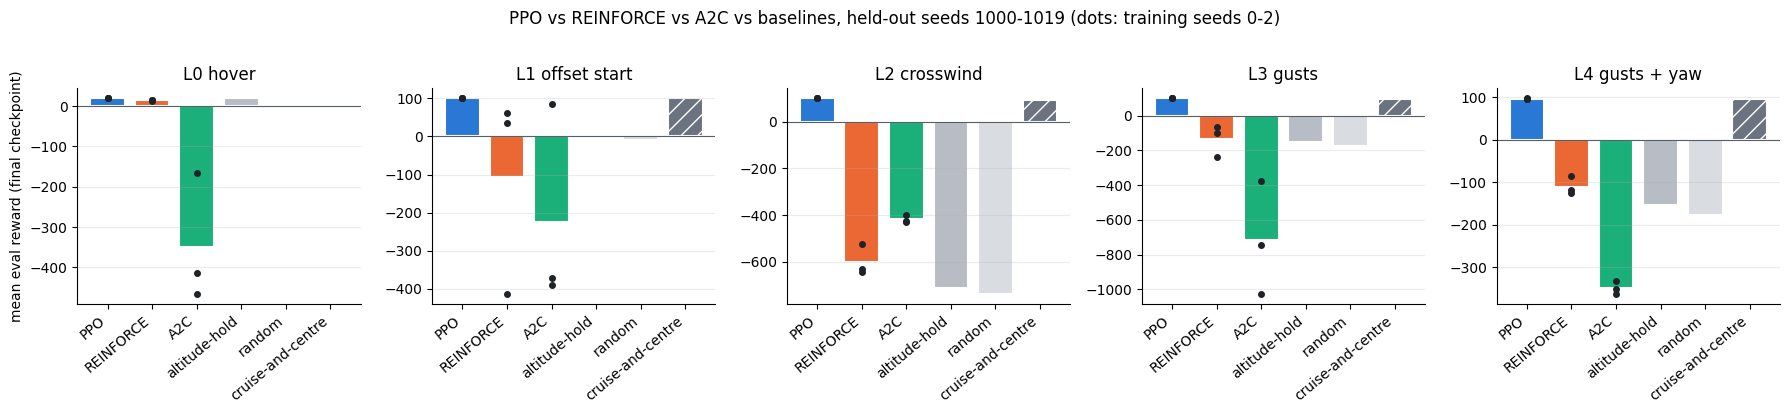

In [6]:
def bar_panel(ax, lv, metric="mean_reward", final_key="final"):
    names = ALGOS + BASELINES
    vals = [np.mean([RUNS[a][(lv, s)][final_key][metric] for s in SEEDS]) for a in ALGOS] + \
           [BASE[(b, lv)][metric] for b in BASELINES]
    bars = ax.bar(range(len(names)), vals, width=0.78, color=[COLOR[n] for n in names],
                  hatch=[HATCH.get(n, "") for n in names], edgecolor="white", linewidth=1.5)
    for i, a in enumerate(ALGOS):
        ax.scatter([i] * len(SEEDS), [RUNS[a][(lv, s)][final_key][metric] for s in SEEDS],
                   color="#1f2328", s=16, zorder=3)
    ax.set_xticks(range(len(names)), [LABEL.get(n, n) for n in names], rotation=40, ha="right")
    ax.axhline(0, color="#57606a", lw=0.8)
    ax.grid(axis="y", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(LEVEL_NAMES[lv])
    return bars

fig, axes = plt.subplots(1, len(LEVELS), figsize=(18, 4))
for ax, lv in zip(axes, LEVELS):
    bar_panel(ax, lv)
axes[0].set_ylabel("mean eval reward (final checkpoint)")
fig.suptitle("PPO vs REINFORCE vs A2C vs baselines, held-out seeds 1000-1019 (dots: training seeds 0-2)", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "comparison_reward_by_level.png", dpi=150, bbox_inches="tight")
plt.show()

### Crash rate and rows finished

The behaviour behind the rewards. L0 is a 1000-step hover with no row to fly, so its finish rate is 0 for every
policy by design.

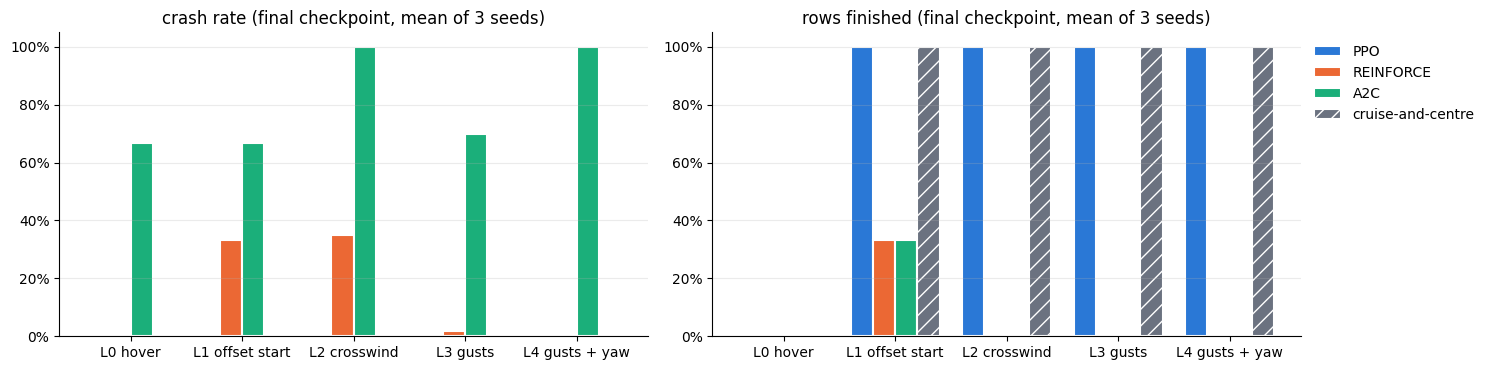

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
names = ALGOS + ["cruise_and_centre"]
width = 0.8 / len(names)
for ax, metric, title in zip(axes, ["crash_rate", "finish_rate"], ["crash rate", "rows finished"]):
    for i, n in enumerate(names):
        vals = [np.mean([RUNS[n][(lv, s)]["final"][metric] for s in SEEDS]) if n in RUNS else BASE[(n, lv)][metric]
                for lv in LEVELS]
        ax.bar(np.arange(len(LEVELS)) + (i - (len(names) - 1) / 2) * width, vals, width, label=LABEL.get(n, n),
               color=COLOR[n], hatch=HATCH.get(n, ""), edgecolor="white", linewidth=1.5)
    ax.set_xticks(range(len(LEVELS)), [LEVEL_NAMES[lv] for lv in LEVELS])
    ax.set_ylim(0, 1.05)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.set_title(f"{title} (final checkpoint, mean of 3 seeds)")
    ax.grid(axis="y", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
axes[1].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.savefig(FIG_DIR / "comparison_crash_finish.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Stability: final vs best checkpoint

`best` is the checkpoint with the highest training return, kept during training; `final` is the policy at the end
of the 1M steps. A large gap means the algorithm found a good policy and then lost it.

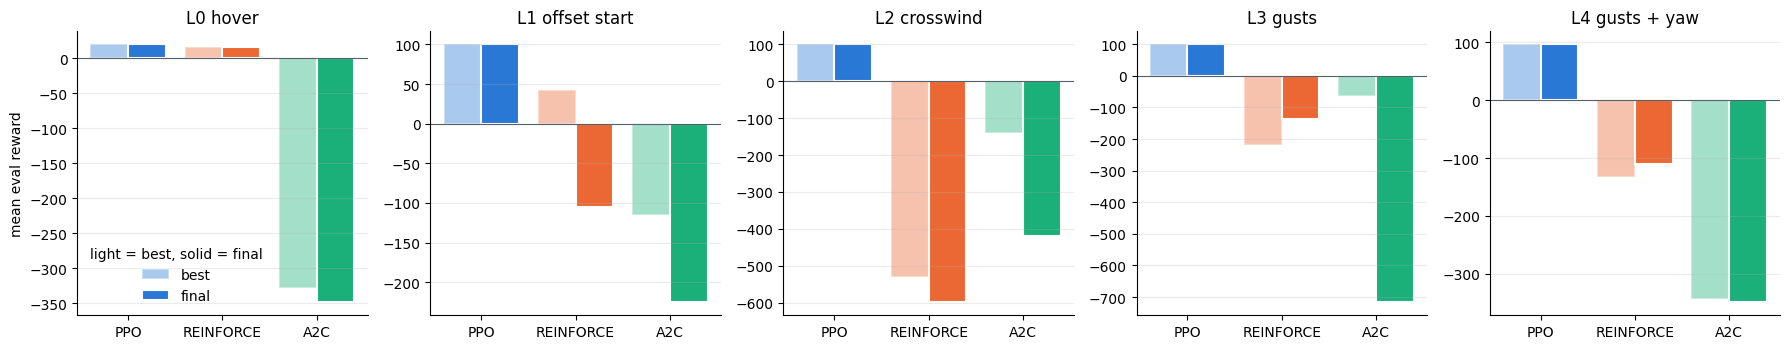

,PPO,REINFORCE,A2C
L0,"3/3 best, 3/3 final","3/3 best, 3/3 final","0/3 best, 0/3 final"
L1,"3/3 best, 3/3 final","1/3 best, 1/3 final","2/3 best, 1/3 final"
L2,"3/3 best, 3/3 final","0/3 best, 0/3 final","2/3 best, 0/3 final"
L3,"3/3 best, 3/3 final","0/3 best, 0/3 final","2/3 best, 0/3 final"
L4,"3/3 best, 3/3 final","0/3 best, 0/3 final","0/3 best, 0/3 final"


In [8]:
fig, axes = plt.subplots(1, len(LEVELS), figsize=(18, 3.6))
for ax, lv in zip(axes, LEVELS):
    for i, a in enumerate(ALGOS):
        best = [RUNS[a][(lv, s)]["best"]["mean_reward"] for s in SEEDS]
        final = [RUNS[a][(lv, s)]["final"]["mean_reward"] for s in SEEDS]
        ax.bar(i - 0.2, np.mean(best), 0.4, color=COLOR[a], alpha=0.4, edgecolor="white", linewidth=1.5,
               label="best" if i == 0 else None)
        ax.bar(i + 0.2, np.mean(final), 0.4, color=COLOR[a], edgecolor="white", linewidth=1.5,
               label="final" if i == 0 else None)
    ax.set_xticks(range(len(ALGOS)), ALGOS)
    ax.axhline(0, color="#57606a", lw=0.8)
    ax.grid(axis="y", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(LEVEL_NAMES[lv])
axes[0].set_ylabel("mean eval reward")
axes[0].legend(frameon=False, title="light = best, solid = final")
plt.tight_layout()
plt.savefig(FIG_DIR / "comparison_final_vs_best.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame({a: {f"L{lv}": f"{sum(cleared(RUNS[a][(lv, s)]['best'], lv) for s in SEEDS)}/3 best, "
                            f"{sum(cleared(RUNS[a][(lv, s)]['final'], lv) for s in SEEDS)}/3 final"
                  for lv in LEVELS} for a in ALGOS})

## 7. Learning curves

Training return per episode (the stochastic policy, so lower than the deterministic evaluation), averaged in
20k-step windows; line = mean of the 3 seeds, band = range across seeds. The dashed line is cruise-and-centre's
evaluation reward on that level, for scale.

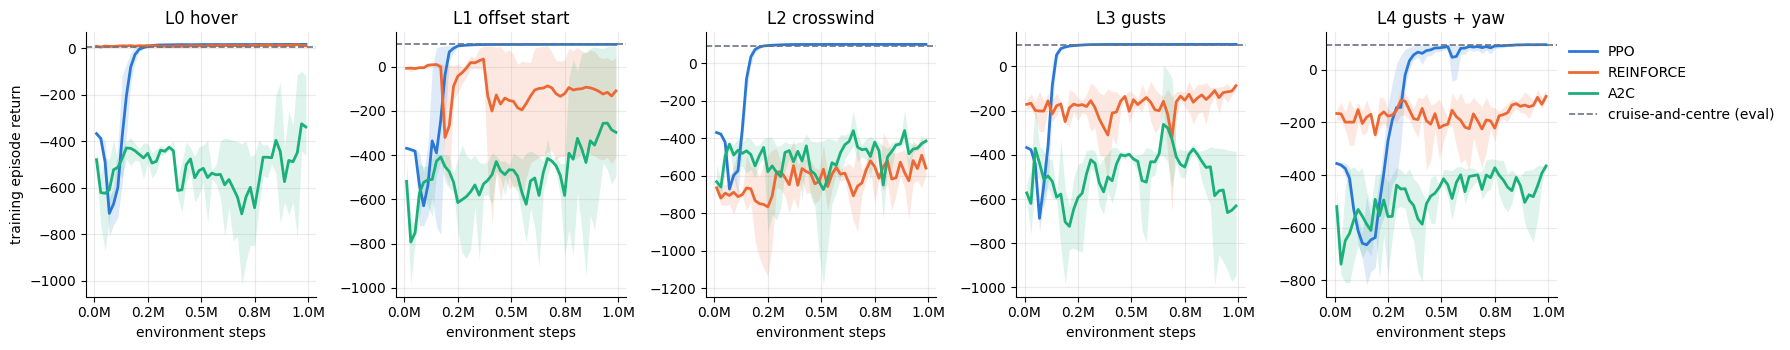

In [9]:
GRID = np.arange(0, 1_000_001, 20_000)

def binned(curve):
    t, r = np.array(curve).T
    idx = np.digitize(t, GRID)
    out = np.array([r[idx == i].mean() if np.any(idx == i) else np.nan for i in range(1, len(GRID))])
    return pd.Series(out).ffill().to_numpy()   # a window with no finished episode keeps the previous value

fig, axes = plt.subplots(1, len(LEVELS), figsize=(18, 3.6), sharex=True)
centres = (GRID[:-1] + GRID[1:]) / 2
for ax, lv in zip(axes, LEVELS):
    for a in ALGOS:
        curves = np.array([binned(RUNS[a][(lv, s)]["curve"]) for s in SEEDS])
        ax.plot(centres, np.nanmean(curves, 0), color=COLOR[a], lw=2, label=a)
        ax.fill_between(centres, np.nanmin(curves, 0), np.nanmax(curves, 0), color=COLOR[a], alpha=0.15, lw=0)
    ax.axhline(BASE[("cruise_and_centre", lv)]["mean_reward"], color=COLOR["cruise_and_centre"], ls="--", lw=1.2,
               label="cruise-and-centre (eval)")
    ax.set_title(LEVEL_NAMES[lv])
    ax.set_xlabel("environment steps")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda x, _: f"{x / 1e6:.1f}M"))
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("training episode return")
axes[-1].legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.savefig(FIG_DIR / "comparison_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Save the comparison

In [10]:
summary.to_csv(RESULTS_DIR / "comparison_summary.csv")
out = dict(
    created=time.strftime("%Y-%m-%dT%H:%M:%S"),
    sources=dict(PPO="ppo_25609227.json", REINFORCE="reinforce_25418551.json",
                 A2C=sorted(p.name for p in RESULTS_DIR.glob("a2c_25399217_L?_seed?_*.json"))),
    eval_seeds=EVAL_SEEDS, reward_config=REWARD_CONFIG,
    cruise_and_centre={f"L{lv}": BASE[("cruise_and_centre", lv)] for lv in LEVELS},
    headline=headline.to_dict(orient="index"),
)
with open(RESULTS_DIR / "comparison.json", "w") as f:
    json.dump(out, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("saved: results/comparison_summary.csv, results/comparison.json and 4 figures in results/figures/")

saved: results/comparison_summary.csv, results/comparison.json and 4 figures in results/figures/
